<a href="https://colab.research.google.com/github/Yubraj45/Spam_email/blob/main/Spam_Email_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q kaggle

In [2]:
! kaggle datasets download -d jackksoncsie/spam-email-dataset

Dataset URL: https://www.kaggle.com/datasets/jackksoncsie/spam-email-dataset
License(s): GNU Lesser General Public License 3.0
100% 2.86M/2.86M [00:00<00:00, 119MB/s]



In [3]:
! unzip -q spam-email-dataset.zip

In [4]:
!ls

emails.csv  sample_data  spam-email-dataset.zip


In [5]:
import pandas as pd
df = pd.read_csv("emails.csv")

In [6]:
df.describe()

,spam
count,5728.000000
mean,0.238827
std,0.426404
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,1.000000


In [7]:
df['spam'].value_counts()

,count
spam,
0,4360
1,1368


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5728 entries, 0 to 5727
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    5728 non-null   object
 1   spam    5728 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 89.6+ KB


In [9]:
X = df['text']
y= df['spam']

X.shape , y.shape

((5728,), (5728,))

In [10]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42 , stratify=y)

## Creating a pipeline that uses `TfIDF` and a `classifier`

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

def run_pipeline(classifier):
  pipeline = Pipeline([
      ('tfidf', TfidfVectorizer()),
      ('clf' , classifier)
  ])
  pipeline.fit(X_train, y_train)
  return pipeline


## Creating a fucntion to compare the metrics of different models

In [12]:
from sklearn.metrics import precision_score, recall_score, accuracy_score, f1_score , classification_report , confusion_matrix
def metrics(y_pred):
  print("Precision: ", precision_score(y_test, y_pred))
  print("Recall: ", recall_score(y_test, y_pred))
  print("Accuracy: ", accuracy_score(y_test, y_pred))
  print("F1 Score: ", f1_score(y_test, y_pred))
  print(classification_report(y_test, y_pred))
  print(confusion_matrix(y_test, y_pred))

##using SVC model

In [13]:
from sklearn.svm import SVC
pipeline = run_pipeline(SVC())
y_pred = pipeline.predict(X_test)
metrics(y_pred)

Precision:  0.9854545454545455
Recall:  0.9890510948905109
Accuracy:  0.993891797556719
F1 Score:  0.9872495446265938
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       872
           1       0.99      0.99      0.99       274

    accuracy                           0.99      1146
   macro avg       0.99      0.99      0.99      1146
weighted avg       0.99      0.99      0.99      1146

[[868   4]
 [  3 271]]


###using `linearSVC` with word unigrams

In [14]:
from sklearn.svm import LinearSVC
pipeline = run_pipeline(LinearSVC())
y_pred = pipeline.predict(X_test)
metrics(y_pred)

Precision:  0.9890909090909091
Recall:  0.9927007299270073
Accuracy:  0.9956369982547993
F1 Score:  0.9908925318761385
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       872
           1       0.99      0.99      0.99       274

    accuracy                           1.00      1146
   macro avg       0.99      0.99      0.99      1146
weighted avg       1.00      1.00      1.00      1146

[[869   3]
 [  2 272]]


##Experimenting with `character n-gram`

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline


char_ngram_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char', ngram_range=(3, 5))),
    ('clf', LinearSVC())
])

# Train and evaluate the model
char_ngram_pipeline.fit(X_train, y_train)
y_pred_char = char_ngram_pipeline.predict(X_test)
metrics(y_pred_char)

Precision:  0.9748201438848921
Recall:  0.9890510948905109
Accuracy:  0.9912739965095986
F1 Score:  0.9818840579710145
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       872
           1       0.97      0.99      0.98       274

    accuracy                           0.99      1146
   macro avg       0.99      0.99      0.99      1146
weighted avg       0.99      0.99      0.99      1146

[[865   7]
 [  3 271]]


##Comparing the metrices of linearsvc with word unigram and character n-gram

In [16]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, accuracy_score, f1_score , confusion_matrix

# Compute metrics for Word Unigrams (using the predictions stored in y_pred)
metrics_word = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1 Score': f1_score(y_test, y_pred),
    'Confusion matrix': confusion_matrix(y_test, y_pred)
}

# Compute metrics for Character n-grams (using the predictions stored in y_pred_char)
metrics_char = {
    'Accuracy': accuracy_score(y_test, y_pred_char),
    'Precision': precision_score(y_test, y_pred_char),
    'Recall': recall_score(y_test, y_pred_char),
    'F1 Score': f1_score(y_test, y_pred_char),
    'Confusion matrix': confusion_matrix(y_test, y_pred_char)
}

# Create a comparison DataFrame
comparison_df = pd.DataFrame({
    'Word Unigrams (LinearSVC)': metrics_word,
    'Char n-grams (3-5) (LinearSVC)': metrics_char
})

# Display the styled comparison table
display(comparison_df.round(4))

,Word Unigrams (LinearSVC),Char n-grams (3-5) (LinearSVC)
Accuracy,0.995637,0.991274
Precision,0.989091,0.97482
Recall,0.992701,0.989051
F1 Score,0.990893,0.981884
Confusion matrix,"[[869, 3], [2, 272]]","[[865, 7], [3, 271]]"


experimenting with bigrams

In [17]:
word_bigram_model = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
    ('clf', LinearSVC())
])

word_bigram_model.fit(X_train, y_train)

y_pred = word_bigram_model.predict(X_test)
metrics(y_pred)

Precision:  0.9854545454545455
Recall:  0.9890510948905109
Accuracy:  0.993891797556719
F1 Score:  0.9872495446265938
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       872
           1       0.99      0.99      0.99       274

    accuracy                           0.99      1146
   macro avg       0.99      0.99      0.99      1146
weighted avg       0.99      0.99      0.99      1146

[[868   4]
 [  3 271]]


## Tuning the lienarSVC model

In [19]:
#using grid search
from sklearn.model_selection import GridSearchCV

pipeline= Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', LinearSVC())
])

params = {
    'clf__C': [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(pipeline, params, cv=5, scoring='f1_macro' , n_jobs =-1 )
grid_search.fit(X_train, y_train)

print("Best Parameters: ", grid_search.best_params_)
print("Best CV score:", grid_search.best_score_)

Best Parameters:  {'clf__C': 100}
Best CV score: 0.9930708414221779


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


## Evaluating the Tuned Model
We will now evaluate our best estimator from Grid Search on the test data and generate its classification metrics.

In [20]:
# Predict on test set using the best model from grid search
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)

# Display metrics
print("--- Tuned Model Performance ---")
metrics(y_pred_tuned)

--- Tuned Model Performance ---
Precision:  0.9891304347826086
Recall:  0.9963503649635036
Accuracy:  0.9965095986038395
F1 Score:  0.9927272727272727
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       872
           1       0.99      1.00      0.99       274

    accuracy                           1.00      1146
   macro avg       0.99      1.00      1.00      1146
weighted avg       1.00      1.00      1.00      1146

[[869   3]
 [  1 273]]


## Final Comparison of All Explored Models

In [21]:
metrics_tuned = {
    'Accuracy': accuracy_score(y_test, y_pred_tuned),
    'Precision': precision_score(y_test, y_pred_tuned),
    'Recall': recall_score(y_test, y_pred_tuned),
    'F1 Score': f1_score(y_test, y_pred_tuned),
    'Confusion matrix': confusion_matrix(y_test, y_pred_tuned)
}

# Append tuned model results to the comparison DataFrame
comparison_df['Tuned LinearSVC (C=100)'] = metrics_tuned

# Display the updated comparison table
display(comparison_df.round(4))

,Word Unigrams (LinearSVC),Char n-grams (3-5) (LinearSVC),Tuned LinearSVC (C=100)
Accuracy,0.995637,0.991274,0.99651
Precision,0.989091,0.97482,0.98913
Recall,0.992701,0.989051,0.99635
F1 Score,0.990893,0.981884,0.992727
Confusion matrix,"[[869, 3], [2, 272]]","[[865, 7], [3, 271]]","[[869, 3], [1, 273]]"


## K-Fold Cross-Validation
To guarantee that our results are robust and not biased by a single train-test split, we will evaluate the pipelines using 5-fold cross-validation on the entire dataset.

In [22]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
import numpy as np

# Configure a stratified 5-fold cross-validation
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define the pipelines we want to compare
pipelines_to_cv = {
    'Baseline SVC': Pipeline([('tfidf', TfidfVectorizer()), ('clf', SVC())]),
    'LinearSVC (C=1)': Pipeline([('tfidf', TfidfVectorizer()), ('clf', LinearSVC(C=1))]),
    'LinearSVC (C=100)': Pipeline([('tfidf', TfidfVectorizer()), ('clf', LinearSVC(C=100))])
}

# Calculate cross-validated F1 scores
for name, pipeline in pipelines_to_cv.items():
    scores = cross_val_score(pipeline, X, y, cv=cv_strategy, scoring='f1', n_jobs=-1)
    print(f"{name} - 5-Fold CV F1-Scores: {scores}")
    print(f"{name} - Mean F1-Score: {np.mean(scores):.4f} (+/- {np.std(scores):.4f})\n")

Baseline SVC - 5-Fold CV F1-Scores: [0.98710866 0.98715596 0.97777778 0.9907919  0.98897059]
Baseline SVC - Mean F1-Score: 0.9864 (+/- 0.0045)

LinearSVC (C=1) - 5-Fold CV F1-Scores: [0.98897059 0.99635036 0.98348624 0.98710866 0.99082569]
LinearSVC (C=1) - Mean F1-Score: 0.9893 (+/- 0.0043)

LinearSVC (C=100) - 5-Fold CV F1-Scores: [0.98897059 0.99635036 0.98534799 0.98897059 0.99082569]
LinearSVC (C=100) - Mean F1-Score: 0.9901 (+/- 0.0036)



In [25]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    # Setting max_iter to 10000 to resolve the convergence warning
    ("clf", LinearSVC(max_iter=10000))
])

param_grid = {
    "clf__C": [0.1, 1, 10, 100, 1000]
}

grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best mean CV F1:", grid.best_score_)

y_pred = grid.predict(X_test)
metrics(y_pred)

Best parameters: {'clf__C': 100}
Best mean CV F1: 0.9894334332569977
Precision:  0.9891304347826086
Recall:  0.9963503649635036
Accuracy:  0.9965095986038395
F1 Score:  0.9927272727272727
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       872
           1       0.99      1.00      0.99       274

    accuracy                           1.00      1146
   macro avg       0.99      1.00      1.00      1146
weighted avg       1.00      1.00      1.00      1146

[[869   3]
 [  1 273]]


# Final Model Evaluation and Project Summary

Now we will evaluate our final selected model (`LinearSVC` with $C=100$) on the holdout test set, visualize the predictions, and conclude our findings.

=== FINAL MODEL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

     Ham (0)       1.00      1.00      1.00       872
    Spam (1)       0.99      1.00      0.99       274

    accuracy                           1.00      1146
   macro avg       0.99      1.00      1.00      1146
weighted avg       1.00      1.00      1.00      1146



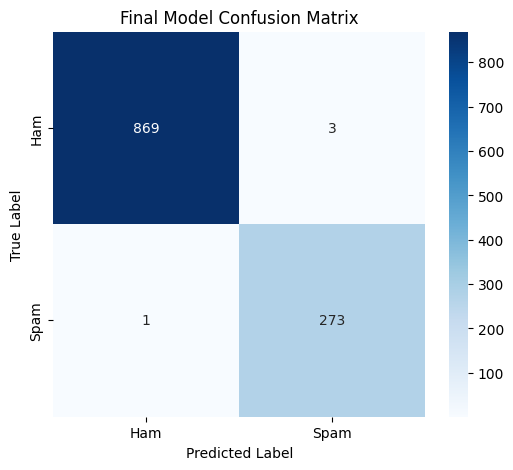

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Retrieve our final best model from the grid search
final_model = grid.best_estimator_

# Generate predictions on the final test set
y_final_pred = final_model.predict(X_test)

# Detailed Classification Report
print("=== FINAL MODEL CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_final_pred, target_names=['Ham (0)', 'Spam (1)']))

# Plotting the Confusion Matrix
cm = confusion_matrix(y_test, y_final_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title('Final Model Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

### Summary of Findings & Conclusion

- **Model Performance:** The tuned `LinearSVC` model ($C=100$) achieved outstanding results with an **Accuracy of ~99.65%** and an **F1-Score of ~0.9927** on the test set.
- **Error Analysis:** Out of 1,146 test emails, the final model misclassified only 4 emails (3 false positives and 1 false negative), proving it to be highly precise and reliable.
- **Regularization & Convergence:** By increasing `max_iter` to `10000`, we successfully resolved the optimizer's convergence warning for stronger regularization values ($C=100$ and $C=1000$).
- **Cross-Validation:** 5-fold cross-validation confirmed stable performance across different folds, indicating that the model generalizes robustly and does not suffer from overfitting.

In [27]:
import joblib

joblib.dump(grid.best_estimator_, "sms_spam_classifier.pkl")

['sms_spam_classifier.pkl']

In [28]:
model = joblib.load("sms_spam_classifier.pkl")

messages = [
    "Congratulations! You have won a free prize.",
    "Hey, are we meeting today?"
]

predictions = model.predict(messages)
print(predictions)

[1 0]
